# Student Information
## Name: Ritika Lund
## Student ID: 023-24-0262
## Section: H
## GitHub:
## Kaggle:

# Part 0 : Setup and the Data 

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve, StratifiedKFold
from sklearn.model_selection import learning_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score

# Task 1
# imbalanced-learn installed

# Task 2

In [2]:
df=pd.read_csv("healthcare-dataset-stroke-data_1.csv")
print("Dataset shape :", df.shape)
print(df.head())
print("Columns name :")
print(df.columns.tolist())
print("Missing values :\n",df.isnull().sum())

print("\nGender counts:")
print(df["gender"].value_counts(dropna=False))

print("\nStroke counts:")
print(df["stroke"].value_counts(dropna=False))

print("\nStroke percentages:")
print(df["stroke"].value_counts(normalize=True, dropna=False) * 100)

Dataset shape : (5110, 12)
      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  
Columns name :
['id', 'gender

# Task 3

In [3]:
df=df.drop(columns=['id'])
print("Shape after removing ID:", df.shape)
df = df[df["gender"] != "Other"].copy()
print("Shape after removing rare gender category:", df.shape)
print("\nRemaining gender counts:")
print(df["gender"].value_counts())
df=pd.get_dummies(
     df,
    columns=df.select_dtypes(include="object").columns,
    dtype=int
)
print("Shape after encoding:", df.shape)
display(df.head())

Shape after removing ID: (5110, 11)
Shape after removing rare gender category: (5109, 11)

Remaining gender counts:
gender
Female    2994
Male      2115
Name: count, dtype: int64
Shape after encoding: (5109, 21)


D:\Temp\ipykernel_21048\624381954.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columns=df.select_dtypes(include="object").columns,


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,ever_married_No,ever_married_Yes,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,0,1,0,1,...,0,1,0,0,0,1,0,1,0,0
1,61.0,0,0,202.21,NaN,1,1,0,0,1,...,0,0,1,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,0,1,0,1,...,0,1,0,0,1,0,0,0,1,0
3,49.0,0,0,171.23,34.4,1,1,0,0,1,...,0,1,0,0,0,1,0,0,0,1
4,79.0,1,0,174.12,24.0,1,1,0,0,1,...,0,0,1,0,1,0,0,0,1,0


# Task 4

In [4]:
X = df.drop(columns=["stroke"])
y = df["stroke"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())
SEED=42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)


print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values in training:", int(X_train.isnull().sum().sum()))
print("Missing values in test:", int(X_test.isnull().sum().sum()))

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled training data:")
display(X_train_scaled.head())

print("\nScaled test data:")
display(X_test_scaled.head())

Features shape: (5109, 20)
Target shape: (5109,)

Target distribution:
stroke
0    4860
1     249
Name: count, dtype: int64
Training features: (4087, 20)
Test features: (1022, 20)

Training target distribution:
stroke
0    3888
1     199
Name: count, dtype: int64

Test target distribution:
stroke
0    972
1     50
Name: count, dtype: int64
Missing values in training: 0
Missing values in test: 0
Scaled training data:


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
845,0.209397,-0.323411,-0.245319,-0.821221,0.549234,0.839671,-0.839671,-0.717905,0.717905,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,-0.994875,0.994875,-0.658432,-0.460478,1.299544,-0.421272
3745,-0.629845,-0.323411,-0.245319,-0.485884,-0.988900,0.839671,-0.839671,1.392942,-1.392942,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,-0.994875,0.994875,-0.658432,-0.460478,1.299544,-0.421272
4184,-0.364822,-0.323411,-0.245319,0.302317,-0.769166,0.839671,-0.839671,-0.717905,0.717905,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,1.005152,-1.005152,-0.658432,-0.460478,1.299544,-0.421272
3410,-0.232310,-0.323411,-0.245319,0.062342,0.497532,-1.190942,1.190942,-0.717905,0.717905,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,1.005152,-1.005152,-0.658432,-0.460478,1.299544,-0.421272
284,-1.292405,-0.323411,-0.245319,-0.527297,0.355351,-1.190942,1.190942,1.392942,-1.392942,2.596253,-0.062692,-1.148132,-0.440434,-0.396402,-0.994875,0.994875,1.518761,-0.460478,-0.769500,-0.421272



Scaled test data:


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
3667,-0.674016,3.092042,-0.245319,-0.497748,0.975775,0.839671,-0.839671,-0.717905,0.717905,2.596253,-0.062692,-1.148132,-0.440434,-0.396402,1.005152,-1.005152,-0.658432,-0.460478,1.299544,-0.421272
2217,-1.778282,-0.323411,-0.245319,-0.281950,-1.208633,0.839671,-0.839671,1.392942,-1.392942,-0.385170,-0.062692,-1.148132,-0.440434,2.522690,-0.994875,0.994875,1.518761,-0.460478,-0.769500,-0.421272
374,0.430250,-0.323411,-0.245319,-0.928896,0.277798,0.839671,-0.839671,-0.717905,0.717905,2.596253,-0.062692,-1.148132,-0.440434,-0.396402,1.005152,-1.005152,-0.658432,-0.460478,-0.769500,2.373761
2392,-0.364822,-0.323411,-0.245319,-0.820997,1.803007,-1.190942,1.190942,-0.717905,0.717905,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,1.005152,-1.005152,-0.658432,-0.460478,1.299544,-0.421272
299,0.651103,-0.323411,-0.245319,-0.259564,0.032214,0.839671,-0.839671,-0.717905,0.717905,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,1.005152,-1.005152,1.518761,-0.460478,-0.769500,-0.421272


# Task 5

In [5]:
print("\nStroke cases in training:", int(y_train.sum()))
print("Stroke cases in test:", int(y_test.sum()))


Stroke cases in training: 199
Stroke cases in test: 50


# Question
## a) In 2-3 lines: how imbalanced is the data? Why did we use stratify=y, and what could go wrong with only a few stroke cases in the test set? 
    The dataset is highly imbalanced, with approximately 4.9% of patients having a stroke and 95.1% not having a stroke. We used stratify=y to preserve the proportion of both classes in the training and test sets. If the test set contains too few stroke cases, the evaluation metrics, especially recall and precision, may become unreliable and may not represent the model's true performance.

# Part 1 : The Accuracy Trap

# Task 1 

In [6]:
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)


baseline_pred = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Accuracy (%):", round(baseline_accuracy * 100, 2))

Baseline Accuracy: 0.9511
Baseline Accuracy (%): 95.11


# Task 2

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
0,0.9521,1.0,0.02,0.0392,0.8393,0.2696


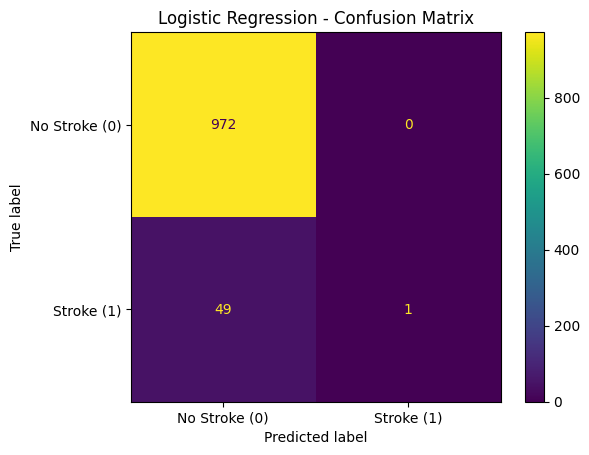

[[972   0]
 [ 49   1]]


In [7]:
lr = LogisticRegression(max_iter=1000, random_state=SEED)
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)
lr_prob = lr.predict_proba(X_test_scaled)[:, 1]
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

lr_results = {
    "Accuracy": accuracy_score(y_test, lr_pred),
    "Precision": precision_score(y_test, lr_pred, zero_division=0),
    "Recall": recall_score(y_test, lr_pred, zero_division=0),
    "F1": f1_score(y_test, lr_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, lr_prob),
    "PR AUC": average_precision_score(y_test, lr_prob)
}

display(pd.DataFrame([lr_results]).round(4))


cm = confusion_matrix(y_test, lr_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Stroke (0)", "Stroke (1)"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

print(cm)

# Task 3

In [8]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    }

# Question 
## a) Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?
    The baseline achieves 95.11% accuracy by predicting every patient as having no stroke. Logistic Regression achieves 95.21% accuracy, but detects only 1 of the 50 stroke patients. Therefore, accuracy is misleading for this imbalanced dataset. Recall, F1-score, PR AUC, and the confusion matrix provide a clearer picture of stroke detection performance.
## b)  Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?
    A false negative occurs when a patient who actually had a stroke is predicted as having no stroke. In a hospital, this could result in a patient being missed for further assessment. Recall is especially important because it measures the proportion of actual stroke cases detected. Precision, F1-score, and PR AUC should also be considered to evaluate false alarms and overall detection quality.

# Part 2 : Underfitting, Overfitting, Bias and Variance 


# Task 1

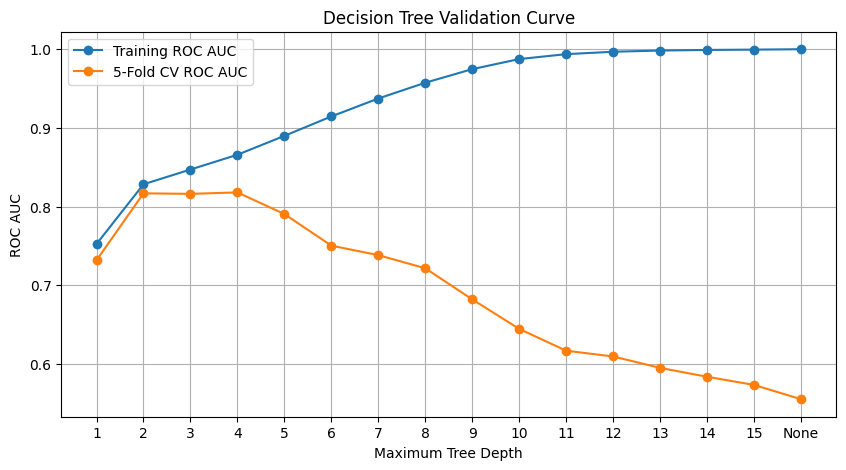

,Depth,Training ROC AUC,CV ROC AUC
0,1,0.7523,0.7317
1,2,0.8283,0.8168
2,3,0.8470,0.8161
3,4,0.8658,0.8180
4,5,0.8898,0.7904
5,6,0.9145,0.7503
6,7,0.9373,0.7382
7,8,0.9574,0.7215
8,9,0.9747,0.6819
9,10,0.9875,0.6444


Best depth: 4
Best mean CV ROC AUC: 0.818


In [9]:
depths = list(range(1, 16)) + [None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

train_scores, cv_scores = validation_curve(
    DecisionTreeClassifier(random_state=SEED),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=depths,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

depth_labels = [str(d) for d in depths]

plt.figure(figsize=(10, 5))
plt.plot(depth_labels, train_mean, marker="o", label="Training ROC AUC")
plt.plot(depth_labels, cv_mean, marker="o", label="5-Fold CV ROC AUC")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("ROC AUC")
plt.title("Decision Tree Validation Curve")
plt.legend()
plt.grid(True)
plt.show()

results_21 = pd.DataFrame({
    "Depth": depth_labels,
    "Training ROC AUC": train_mean,
    "CV ROC AUC": cv_mean
})

display(results_21.round(4))

best_index = np.argmax(cv_mean)
print("Best depth:", depth_labels[best_index])
print("Best mean CV ROC AUC:", round(cv_mean[best_index], 4))

# Task 2

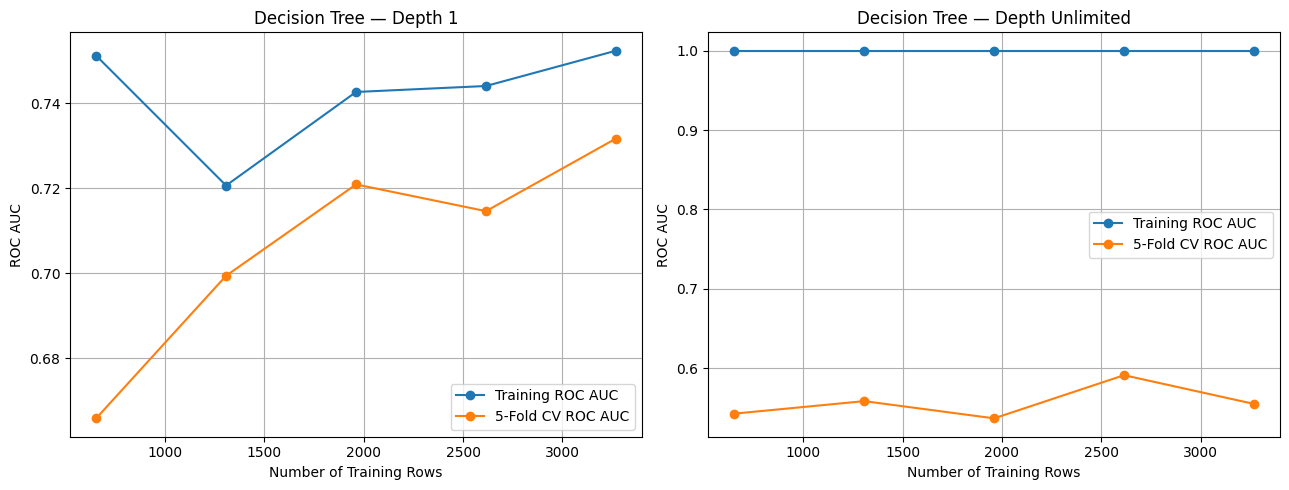

,Depth,Training Rows,Training ROC AUC,CV ROC AUC
0,1,653,0.7512,0.6659
1,1,1307,0.7206,0.6994
2,1,1961,0.7426,0.7209
3,1,2615,0.7440,0.7146
4,1,3269,0.7523,0.7317
5,None,653,1.0000,0.5427
6,None,1307,1.0000,0.5585
7,None,1961,1.0000,0.5368
8,None,2615,1.0000,0.5912
9,None,3269,1.0000,0.5550


In [11]:
train_sizes_fraction = np.linspace(0.2, 1.0, 5)
depth_options = [1, None]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

learning_results = []

for ax, depth in zip(axes, depth_options):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)

    sizes, train_scores, cv_scores = learning_curve(
        tree,
        X_train,
        y_train,
        train_sizes=train_sizes_fraction,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        shuffle=True,
        random_state=SEED
    )

    train_mean = train_scores.mean(axis=1)
    cv_mean = cv_scores.mean(axis=1)

    ax.plot(sizes, train_mean, marker="o", label="Training ROC AUC")
    ax.plot(sizes, cv_mean, marker="o", label="5-Fold CV ROC AUC")
    ax.set_xlabel("Number of Training Rows")
    ax.set_ylabel("ROC AUC")
    ax.set_title(f"Decision Tree — Depth {depth if depth else 'Unlimited'}")
    ax.legend()
    ax.grid(True)

    for i in range(len(sizes)):
        learning_results.append({
            "Depth": str(depth),
            "Training Rows": sizes[i],
            "Training ROC AUC": train_mean[i],
            "CV ROC AUC": cv_mean[i]
        })

plt.tight_layout()
plt.show()

display(pd.DataFrame(learning_results).round(4))

# Task 3

In [14]:
rng = np.random.default_rng(SEED)
n_bootstraps = 40
depth_options = [1, 3, None]

bootstrap_results = []
bootstrap_predictions = {}

for depth in depth_options:
    predictions = []

    for i in range(n_bootstraps):
       
        sample_indices = rng.integers(0, len(X_train), size=len(X_train))

        X_boot = X_train.iloc[sample_indices]
        y_boot = y_train.iloc[sample_indices]

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED + i
        )
        tree.fit(X_boot, y_boot)

        
        class_1_index = list(tree.classes_).index(1)
        probabilities = tree.predict_proba(X_test)[:, class_1_index]

        predictions.append(probabilities)

    predictions = np.array(predictions)
    bootstrap_predictions[str(depth)] = predictions

    # Variance across trees for each test patient, then average
    mean_prediction_variance = np.var(predictions, axis=0).mean()

    # Average ROC AUC of individual trees
    individual_auc = [
        roc_auc_score(y_test, predictions[i])
        for i in range(n_bootstraps)
    ]

    # ROC AUC after averaging predictions from all trees
    averaged_predictions = predictions.mean(axis=0)
    averaged_auc = roc_auc_score(y_test, averaged_predictions)

    bootstrap_results.append({
        "Depth": str(depth),
        "Mean Prediction Variance": mean_prediction_variance,
        "Mean Individual Tree ROC AUC": np.mean(individual_auc),
        "ROC AUC of Averaged Predictions": averaged_auc
    })

bootstrap_df = pd.DataFrame(bootstrap_results)
display(bootstrap_df.round(4))

,Depth,Mean Prediction Variance,Mean Individual Tree ROC AUC,ROC AUC of Averaged Predictions
0,1,0.0007,0.7623,0.8132
1,3,0.0017,0.7963,0.8339
2,None,0.0422,0.5526,0.7682


# Questions
## a)From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone. 
    Depth 1 shows underfitting, with training AUC = 0.8283 and CV AUC = 0.8168. Depths 5 and above increasingly overfit because training AUC rises while CV AUC falls. For example, at depth 10, training AUC = 0.9937 but CV AUC = 0.6167. I would choose depth 4, which has the highest CV AUC of 0.8180, giving the best generalization among the tested depths.
## b)From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one? 
    High bias occurs when training and CV scores are both relatively low and close together, as with the shallow tree. High variance occurs when training performance is much higher than CV performance, as with the unlimited-depth tree. Adding more training rows may reduce high variance, but it will not necessarily fix high bias; a more complex model may be needed. In my learning curves, more rows did not eliminate the large gap for the unlimited-depth tree.
## c)From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4). 
    Prediction variance increases with depth: 0.0007 at depth 1, 0.0017 at depth 3, and 0.0422 at unlimited depth. Averaging predictions improves ROC AUC for all three depths. For depth 3, AUC improves from 0.7963 for individual trees on average to 0.8339 for averaged predictions. This is related to Random Forests, which combine predictions from multiple trees to reduce variance and improve generalization.
## d)In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit? 
    The bias–variance trade-off means balancing a model that is too simple to learn important patterns against one that is too complex and learns noise from the training data.
    - Depth 1: Higher bias, low variance; likely underfits.
    - Depth 3: A more balanced model, with better performance in the bootstrap experiment.
    - Depth None: Low training error but high variance and severe overfitting.
    The goal is not to maximize training performance, but to choose a model that performs well on unseen data.

# Part 3: ROC, AUC, Precision-Recall and Thresholds

# Task 1

,Model,ROC AUC,PR AUC (Average Precision)
0,Logistic Regression,0.8393,0.2696
1,Decision Tree (depth=3),0.7956,0.1621
2,Random Forest,0.8215,0.2183


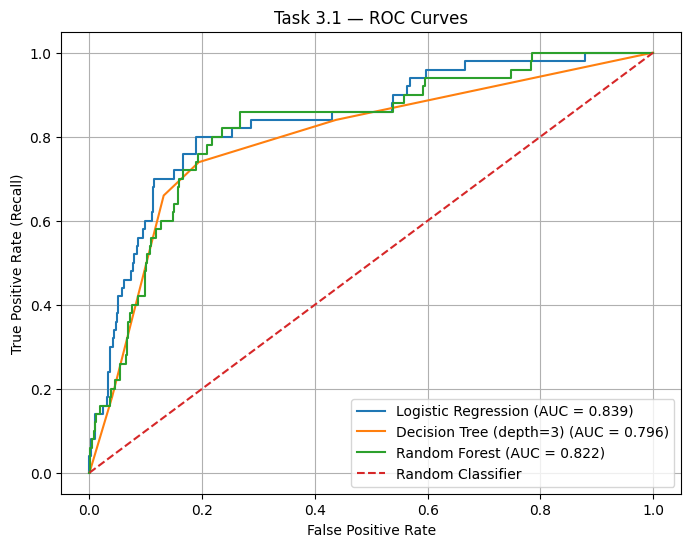

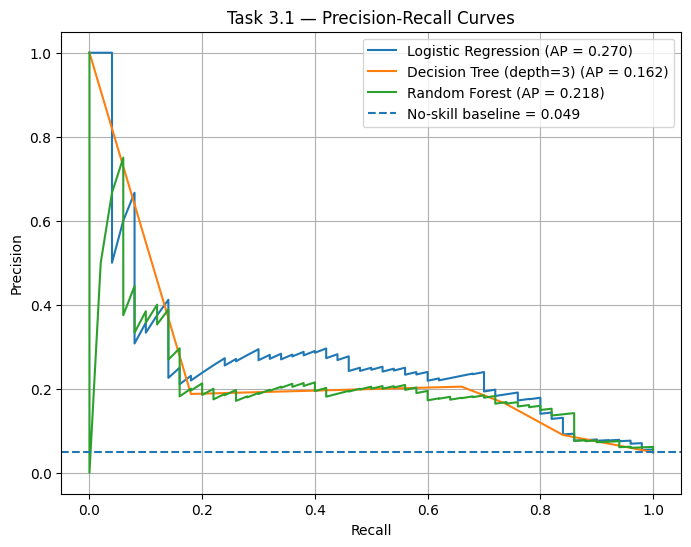

Test-set stroke prevalence: 0.0489


In [18]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=SEED
    ),
    "Decision Tree (depth=3)": DecisionTreeClassifier(
        max_depth=3, random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED,
        n_jobs=-1
    )
}

# Logistic Regression uses scaled data; tree models use original data.
X_train_models = {
    "Logistic Regression": X_train_scaled,
    "Decision Tree (depth=3)": X_train,
    "Random Forest": X_train
}

X_test_models = {
    "Logistic Regression": X_test_scaled,
    "Decision Tree (depth=3)": X_test,
    "Random Forest": X_test
}

model_probabilities = {}
model_results = []

for name, model in models.items():
    model.fit(X_train_models[name], y_train)

    probabilities = model.predict_proba(X_test_models[name])[:, 1]
    model_probabilities[name] = probabilities

    model_results.append({
        "Model": name,
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "PR AUC (Average Precision)": average_precision_score(
            y_test, probabilities
        )
    })

display(pd.DataFrame(model_results).round(4))

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Task 3.1 — ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

stroke_rate = y_test.mean()

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    plt.plot(recall, precision, label=f"{name} (AP = {ap:.3f})")

plt.axhline(
    y=stroke_rate,
    linestyle="--",
    label=f"No-skill baseline = {stroke_rate:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Task 3.1 — Precision-Recall Curves")
plt.legend()
plt.grid(True)
plt.show()

print("Test-set stroke prevalence:", round(stroke_rate, 4))


# Task 2

In [20]:
lr_threshold_model = LogisticRegression(
    max_iter=1000, random_state=SEED
)

oof_probabilities = cross_val_predict(
    lr_threshold_model,
    X_train_scaled,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

threshold_candidates = np.sort(np.unique(oof_probabilities))
threshold_results = []

for threshold in threshold_candidates:
    oof_pred = (oof_probabilities >= threshold).astype(int)
    recall = recall_score(y_train, oof_pred, zero_division=0)
    precision = precision_score(y_train, oof_pred, zero_division=0)

    if recall >= 0.80:
        threshold_results.append({
            "Threshold": threshold,
            "Recall": recall,
            "Precision": precision
        })

if threshold_results:
    threshold_df = pd.DataFrame(threshold_results)
    # Highest threshold that still achieves recall >= 0.80
    chosen_row = threshold_df.loc[threshold_df["Threshold"].idxmax()]
    chosen_threshold = chosen_row["Threshold"]

    print("Chosen threshold:", round(chosen_threshold, 4))
    print("OOF recall:", round(chosen_row["Recall"], 4))
    print("OOF precision:", round(chosen_row["Precision"], 4))
else:
    chosen_threshold = 0.5
    print("No threshold achieved recall >= 0.80; using 0.5 as fallback.")



lr_final = LogisticRegression(max_iter=1000, random_state=SEED)
lr_final.fit(X_train_scaled, y_train)

test_probabilities = lr_final.predict_proba(X_test_scaled)[:, 1]
threshold_pred = (test_probabilities >= chosen_threshold).astype(int)

threshold_cm = confusion_matrix(y_test, threshold_pred)

threshold_recall = recall_score(
    y_test, threshold_pred, zero_division=0
)
threshold_precision = precision_score(
    y_test, threshold_pred, zero_division=0
)

tn, fp, fn, tp = threshold_cm.ravel()

print("Chosen threshold:", round(chosen_threshold, 4))
print("Test Recall:", round(threshold_recall, 4))
print("Test Precision:", round(threshold_precision, 4))
print("Confusion Matrix:\n", threshold_cm)
print("Patients flagged as stroke:", int(tp + fp))
print("False alarms:", int(fp))
print("Missed stroke cases:", int(fn))

Chosen threshold: 0.0507
OOF recall: 0.804
OOF precision: 0.1357
Chosen threshold: 0.0507
Test Recall: 0.82
Test Precision: 0.1344
Confusion Matrix:
 [[708 264]
 [  9  41]]
Patients flagged as stroke: 305
False alarms: 264
Missed stroke cases: 9


# Questions
## a)In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is much higher than 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it? 
    Logistic Regression has ROC AUC 0.8393, meaning it can rank stroke patients above non-stroke patients reasonably well. However, at the default threshold of 0.5, many stroke probabilities fall below the cutoff, causing false negatives. Lowering the threshold to 0.0507 increased test recall to 0.82, detecting 41 of the 50 stroke cases, but also increased false alarms to 264. The threshold determines how predicted probabilities are converted into class labels.
## b)Which metric curve is more informative for this data - ROC or Precision-Recall - and why? Use the no-skill line in your answer. 
    The Precision–Recall curve is particularly informative for this highly imbalanced dataset because only 4.89% of test patients had a stroke. It shows the trade-off between detecting stroke cases and avoiding false alarms. The no-skill baseline on the PR curve is the positive-class prevalence, approximately 0.0489. ROC AUC is still useful for evaluating how well the models rank cases.
## c)At your chosen threshold, what is the price the hospital pays for the higher recall? Is it acceptable? Argue both sides in 3-4 lines. 
    Increasing recall reduces missed stroke cases but usually increases false alarms, which may lead to unnecessary tests, additional workload, and resource use.
    
    At threshold 0.0507, the model achieved:
    - Recall: 82% detected 41 of 50 stroke cases.
    - Precision: 13.44%  41 of 305 flagged patients actually had a stroke.
    - False alarms: 264.
    - Missed stroke cases: 9.
    For an initial hospital screening tool, I would consider this trade-off if the flagged patients receive appropriate follow-up assessment. However, the threshold should be clinically validated, and the model should support not replace medical judgment.

# Part 4 : Undersampling, Oversampling and SMOTE

# Task 1